# 04. E2 — затухающие счётчики вместо окон

**Вопрос:** можно ли убрать ещё и ручной выбор окон? В E0 окна (7, 30 дней, вся история) выбраны вручную, в E1 — перебором из семи. Анализ E1 показал, что признаки с разными окнами **взаимозаменяемы** : отбор берёт то 90 дней, то всю историю, а качество то же. Значит, окна можно заменить одним плавным механизмом.

**Затухающий счётчик:** событие возрастом $a$ дней входит в признак с весом $2^{-a/h}$, где $h$ — **период полураспада**: событие $h$ дней назад весит половину, $2h$ — четверть. Маленькое $h$ — «помнит последние дни», большое — «почти вся история». Вместо выбора окон подбираем одно число $h$ на val_a.

**Признаки:** те же ключи, что в E1  = **48 признаков на одно h**. Считаются на начало дня, как E0/E1 (тесты `tests/test_decay.py`: нет утечки; значения совпадают с прямым подсчётом по формуле).

In [1]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

import json
from src.candidates import load_candidates
from src.decay import E2_DIR, HALF_LIVES, load_decay
from src.grammar import FAMILIES
from src.metrics import evaluate
from src.models import LGB_PARAMS, train_lgb, make_logreg
from src.features import E0_FEATURES

ART = ROOT / "artifacts" / "E2"
res0 = pickle.load(open(ROOT / "artifacts" / "E0" / "results.pkl", "rb"))
res1 = pickle.load(open(ROOT / "artifacts" / "E1" / "results.pkl", "rb"))

## 1. Стоимость генерации

In [ ]:
#из build_e2_features
blog = pl.read_ndjson(E2_DIR / "build_log.jsonl")
gen_time = blog["seconds"].sum()
disk_gb = sum(p.stat().st_size for p in E2_DIR.glob("*.parquet")) / 1024**3

display(blog.pivot(on="h", index="family", values="seconds").with_columns(pl.exclude("family").round(1)))
print(f"Все семейства × {len(HALF_LIVES)} значений h: {gen_time:.0f} с, пик памяти {blog['peak_rss_gb'].max():.1f} ГБ, на диске {disk_gb:.1f} ГБ")
print(f"Одно h (48 признаков): ~{gen_time / len(HALF_LIVES):.0f} с")

family,3,7,14,30,60,120,240,480
str,f64,f64,f64,f64,f64,f64,f64,f64
"""u""",1.4,1.4,1.4,1.5,1.6,1.6,1.8,1.8
"""i""",7.0,6.8,7.0,7.6,7.1,7.5,6.8,7.5
"""a""",4.0,4.0,4.0,4.0,4.0,4.0,4.1,4.4
"""ui""",9.5,9.4,9.5,9.6,9.4,9.4,11.8,11.4
"""ua""",9.4,10.2,9.7,9.8,10.3,9.8,10.2,11.1
"""ul""",2.9,2.9,2.8,2.9,2.9,2.9,3.5,3.4


Все семейства × 8 значений h: 287 с, пик памяти 4.7 ГБ, на диске 2.1 ГБ
Одно h (48 признаков): ~36 с


## 2. Подбор h на val_a

Лёгкая модель (как при отборе E1), подвыборка train 600 тыс. строк, качество — GAUC на val_a (`scripts/run_e2_tuning.py`):
1. **одно h для всех семейств**;
2. **своё h для каждого семейства** — покоординатно: от лучшего общего h меняем h одного семейства, остальные фиксированы 
3. **все h сразу** (288 признаков) — нужны ли несколько временных масштабов одновременно

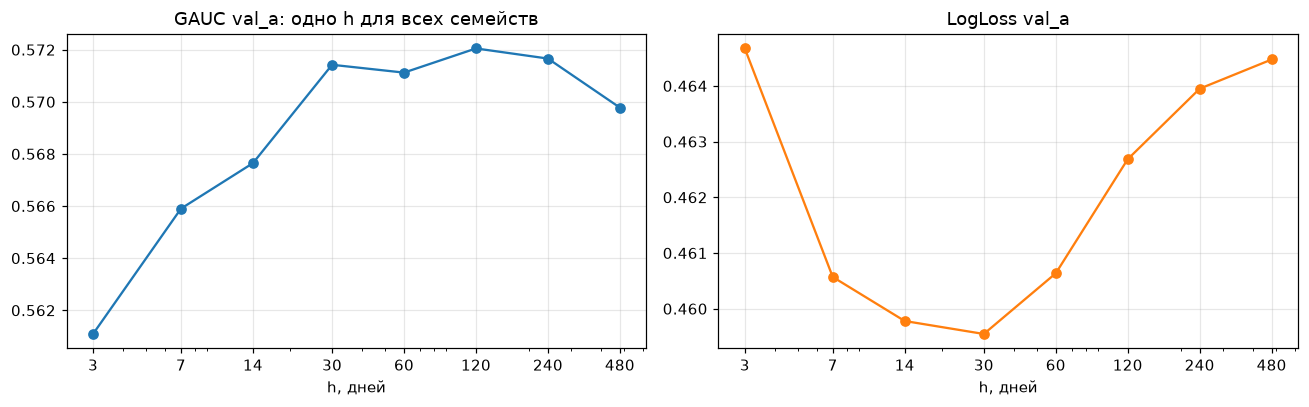

h,n_features,gauc,logloss,trees
i64,i64,f64,f64,i64
3,48,0.5611,0.4647,55
7,48,0.5659,0.4606,73
14,48,0.5676,0.4598,58
30,48,0.5714,0.4595,70
60,48,0.5711,0.4606,69
120,48,0.572,0.4627,75
240,48,0.5717,0.4639,95
480,48,0.5698,0.4645,92


In [ ]:
trials = pl.DataFrame(json.loads((ART / "tuning.json").read_text()))
best_cfg = json.loads((ART / "best_config.json").read_text())

glob = trials.filter(pl.col("stage") == "global").with_columns(
    # у всех одинаковое h, берем ["u"][0]
    pl.col("config").map_elements(lambda c: c["u"][0], return_dtype=pl.Int64).alias("h")).sort("h")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(glob["h"], glob["gauc"], "o-")
axes[0].set_xscale("log")
axes[0].set_xticks(HALF_LIVES, HALF_LIVES)
axes[0].set_xlabel("h, дней")
axes[0].set_title("GAUC val_a: одно h для всех семейств")
axes[1].plot(glob["h"], glob["logloss"], "o-", color="C1")
axes[1].set_xscale("log")
axes[1].set_xticks(HALF_LIVES, HALF_LIVES)
axes[1].set_xlabel("h, дней")
axes[1].set_title("LogLoss val_a")

plt.tight_layout()
plt.show()
display(glob.select("h", "n_features", pl.col("gauc").round(4), pl.col("logloss").round(4), "trees"))

- выбор устойчив : 60,120 ил 240 - находятся рядом
- короткая память - плохая
- logloss and gauc расходятся - выберем все таки по gauc, как и говорили, что она главная метрика, ранжирование не починишь калибровкой

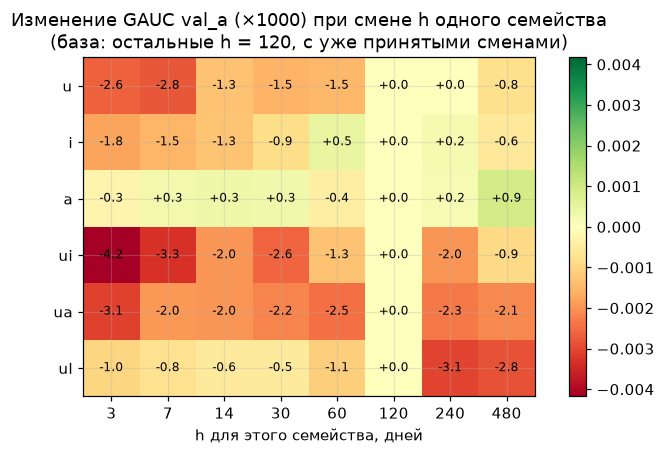

Лучшая конфигурация по семействам: {'u': [120], 'i': [120], 'a': [480], 'ui': [120], 'ua': [120], 'ul': [120]}


In [ ]:

H0 = best_cfg["global_h"]
MIN_GAIN = 0.0005

#справочник испытания: "когфиг : GAUC"
#кофиг - у каждой семьи какой h
lookup = {json.dumps(t["config"], sort_keys=True): t["gauc"] for t in json.loads((ART / "tuning.json").read_text())}
#функция получения gauc для  конфигурации
G = lambda cfg: lookup[json.dumps(cfg, sort_keys=True)]
#стартовая, для всех семей best global
cur = {f: [H0] for f in FAMILIES}
best = G(cur)

rows = []
for fam in FAMILIES:
    base_g = G(cur)
    #создаем копию словаря с заменой по какой-то семье
    res_f = {h: G({**cur, fam: [h]}) for h in HALF_LIVES}
    #один ряд на тепловой карте - что будет, если мы изменяем семейство
    #между строками сранвивать нельзя, разный будет отсчет - bset, cur
    # находим не лучшее h вообще, а при текущих значения остальных
    # 8^6  конфигунраций как-то многовато
    rows += [{"семейство": fam, "h": h, "delta": g - base_g} for h, g in res_f.items()]
    for h, g in res_f.items():
        if g > best + MIN_GAIN:
            best, cur = g, {**cur, fam: [h]}

pf = pl.DataFrame(rows)

# через select задаем порядок семейства
M = pf.pivot(on="h", index="семейство", values="delta", maintain_order=True).select("семейство", *[str(h) for h in HALF_LIVES])

fig, ax = plt.subplots(figsize=(8, 4))
#для границы цветовой шкалы
V = M.drop("семейство").to_numpy()
lim = np.nanmax(np.abs(V))
im = ax.imshow(V, cmap="RdYlGn", vmin=-lim, vmax=lim)


for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        ax.text(j, i, f"{V[i, j] * 1000:+.1f}", ha="center", va="center", fontsize=8)


ax.set_xticks(range(len(HALF_LIVES)), HALF_LIVES)
ax.set_yticks(range(M.height), M["семейство"])
ax.set_xlabel("h для этого семейства, дней")
ax.set_title(f"Изменение GAUC val_a (×1000) при смене h одного семейства\n(база: остальные h = {H0}, с уже принятыми сменами)")
plt.colorbar(im, ax=ax)
plt.show()


print("Лучшая конфигурация по семействам:", best_cfg["per_family"])

- короткая память у всех плоха
- к 120 дню прямо все выравниваются
- ul: пользователь * трек - после 120 дней видимо предпочтения меняются

In [6]:
summary = (trials.group_by("stage", maintain_order=True)
           .agg(pl.col("gauc").max().round(4).alias("лучший GAUC val_a"), pl.col("n_features").first().alias("признаков"),
                pl.len().alias("испытаний"), pl.col("seconds").sum().round(0).alias("время, с")))
display(summary)
tune_time = trials["seconds"].sum()
print(f"Весь подбор: {len(trials)} обучений лёгкой модели, {tune_time / 60:.0f} мин")

stage,лучший GAUC val_a,признаков,испытаний,"время, с"
str,f64,i64,u32,f64
"""global""",0.572,48,8,62.0
"""per_fam1""",0.573,48,42,332.0
"""per_fam2""",0.5716,48,14,106.0
"""all_h""",0.574,384,1,52.0


Весь подбор: 65 обучений лёгкой модели, 9 мин


### Выбор конфигурации

Правило то же, что в E1: берём конфигурацию с **лучшим GAUC на val_a**; если выигрыш более сложной конфигурации меньше 0.0005 (уровень шума одного шага жадного отбора), берём более простую.

**Все h сразу (384 признака) в выбор не входит — из-за памяти** 

In [ ]:
cands_cfg = [
    ("одно h", {f: [H0] for f in FAMILIES}),
    ("h по семействам", best_cfg["per_family"]),
]
ref = ("все h (ориентир, не выбирается)", {f: HALF_LIVES for f in FAMILIES})

def val_a_gauc(cfg):
    key = json.dumps(cfg, sort_keys=True)
    #берет первое такое значение и останавливается, если находит такую конфигурацию
    return next(t["gauc"] for t in json.loads((ART / "tuning.json").read_text()) if json.dumps(t["config"], sort_keys=True) == key)

scores = [(n, c, val_a_gauc(c)) for n, c in cands_cfg]
#стартуем с самого легкого - h0 у всех один
choice = scores[0]
for s in scores[1:]:
    #под вторым номером gauc 
    if s[2] > choice[2] + 0.0005:
        choice = s

CFG_NAME, CFG, _ = choice
for n, c, g in [*scores, (*ref, val_a_gauc(ref[1]))]:
    print(f"{n:32s} GAUC val_a {g:.4f}" + ("   <- выбрано" if n == CFG_NAME else ""))
print("Конфигурация:", CFG)

одно h                           GAUC val_a 0.5720
h по семействам                  GAUC val_a 0.5730   ← выбрано
все h (ориентир, не выбирается)  GAUC val_a 0.5740
Конфигурация: {'u': [120], 'i': [120], 'a': [480], 'ui': [120], 'ua': [120], 'ul': [120]}


## 4. Финальные модели

Как в E0 и E1: `LGB_PARAMS` с ранней остановкой по val_a на **полном** train, логрегрессия `make_logreg`. Плюс **E0 + E2** — даёт ли затухание что-то сверх ручных признаков.

In [ ]:
cands = load_candidates()
parts = {p: cands.filter(pl.col("part") == p) for p in ["train", "val_a", "val_b"]}
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")

t0 = time.perf_counter()
M2 = {p: load_decay(d, CFG).join(feats0, on="row_id", how="left", maintain_order="left") for p, d in parts.items()}
load_time = time.perf_counter() - t0

F2 = [c for c in M2["train"].columns if "__h" in c]
y = {p: d["label"].to_numpy() for p, d in parts.items()}
print(f"Признаков E2: {len(F2)}; загрузка {load_time:.0f} с; пиковая память {peak_ram_gb():.1f} ГБ")

models, cost = {}, {"load_s": load_time}
for name, cols in [("E2", F2), ("E0 + E2", [*E0_FEATURES, *F2])]:
    m, hist, sec = train_lgb(M2["train"].select(cols).to_numpy(), y["train"], M2["val_a"].select(cols).to_numpy(), y["val_a"])
    models[name] = (m, cols)
    cost[f"lgb_{name}_s"] = sec
    print(f"LightGBM {name}: {len(cols)} признаков, {m.best_iteration} деревьев, {sec:.0f} с")


t0 = time.perf_counter()
lr_model = make_logreg(F2).fit(M2["train"].select(F2).to_numpy(), y["train"])
cost["lr_E2_s"] = time.perf_counter() - t0
print(f"Логрегрессия E2: {cost['lr_E2_s']:.0f} с; пиковая память {peak_ram_gb():.1f} ГБ")

Признаков E2: 48; загрузка 4 с; пиковая память 3.2 ГБ


LightGBM E2: 48 признаков, 290 деревьев, 65 с


LightGBM E0 + E2: 84 признаков, 258 деревьев, 98 с


Логрегрессия E2: 76 с; пиковая память 5.9 ГБ


In [ ]:
rows, preds = [], []
for p in ["val_a", "val_b"]:
    d = parts[p].select("row_id", "uid", "day", "part", "label").with_columns(
        **{f"p_{n}": pl.Series(m.predict(M2[p].select(cols).to_numpy(), num_iteration=m.best_iteration)) for n, (m, cols) in models.items()},
        p_lr=pl.Series(lr_model.predict_proba(M2[p].select(F2).to_numpy())[:, 1]))
    
    preds.append(d)
    
    for name, col in [("E2 LightGBM", "p_E2"), ("E0 + E2 LightGBM", "p_E0 + E2"), ("E2 логрегрессия", "p_lr")]:
        rows.append({"модель": name, "часть": p, **evaluate(d, col)})

preds = pl.concat(preds)
new = pl.DataFrame(rows)
old = pl.concat([res0["metrics"].filter(pl.col("модель").is_in(["LightGBM", "логрегрессия"])).with_columns(("E0 " + pl.col("модель")).alias("модель")),
                 res1["metrics"].filter(pl.col("модель").str.contains("E1"))], how="vertical_relaxed").select(new.columns)
metrics = pl.concat([old, new], how="vertical_relaxed")


display(metrics.sort("часть", "модель").with_columns(pl.col(c).round(4) for c in ["logloss", "roc_auc", "gauc", "ndcg@10", "recall@10"]))

модель,часть,logloss,roc_auc,ndcg@10,recall@10,gauc,groups
str,str,f64,f64,f64,f64,f64,i64
"""E0 + E1 LightGBM""","""val_a""",0.4554,0.832,0.7635,0.5152,0.5765,15808
"""E0 + E2 LightGBM""","""val_a""",0.4546,0.8327,0.7648,0.5165,0.5769,15808
"""E0 LightGBM""","""val_a""",0.4584,0.8294,0.761,0.5143,0.574,15808
"""E0 логрегрессия""","""val_a""",0.4688,0.8227,0.7526,0.511,0.5657,15808
"""E1 LightGBM""","""val_a""",0.4678,0.8212,0.7616,0.5143,0.5725,15808
"""E1 логрегрессия""","""val_a""",0.4776,0.8144,0.7527,0.5107,0.5645,15808
"""E2 LightGBM""","""val_a""",0.4612,0.8273,0.7635,0.5149,0.5759,15808
"""E2 логрегрессия""","""val_a""",0.4714,0.8201,0.7525,0.5103,0.5657,15808
"""E0 + E1 LightGBM""","""val_b""",0.4524,0.8286,0.7672,0.512,0.5733,15622


### Значимость разницы: парный бутстреп по группам «пользователь × день» (val_b)

In [ ]:
def group_gauc(d, col):
    return (d.with_columns(r=pl.col(col).rank("average").over("uid", "day"),
                           npos=pl.col("label").sum().over("uid", "day"), n=pl.len().over("uid", "day"))
            .filter((pl.col("npos") > 0) & (pl.col("npos") < pl.col("n")))
            .group_by("uid", "day")
            .agg(g=((pl.col("r") * pl.col("label")).sum() - pl.col("npos").first() * (pl.col("npos").first() + 1) / 2)
                 / (pl.col("npos").first() * (pl.col("n").first() - pl.col("npos").first())))
            .sort("uid", "day")["g"].to_numpy())


vb_p = (preds.filter(pl.col("part") == "val_b")
        .join(res0["predictions"].select("row_id", pl.col("p_lgb").alias("p_E0")), on="row_id", how="left", maintain_order="left")
        .join(res1["predictions"].select("row_id", "p_E1"), on="row_id", how="left", maintain_order="left"))


G = {c: group_gauc(vb_p, c) for c in ["p_E0", "p_E1", "p_E2", "p_E0 + E2"]}
idx = np.random.default_rng(0).integers(0, len(G["p_E0"]), (1000, len(G["p_E0"])))
boot = []

for name, a, b in [("E2 − E0", "p_E2", "p_E0"), ("E2 − E1", "p_E2", "p_E1"), ("(E0 + E2) − E0", "p_E0 + E2", "p_E0")]:
    diff = G[a] - G[b]
    bs = diff[idx].mean(1)
    boot.append({"сравнение": name, "разница GAUC": round(diff.mean(), 4),
                 "95% ДИ": f"[{np.quantile(bs, 0.025):+.4f}; {np.quantile(bs, 0.975):+.4f}]"})
boot = pl.DataFrame(boot)
boot

сравнение,разница GAUC,95% ДИ
str,f64,str
"""E2 − E0""",0.0036,"""[+0.0010; +0.0062]"""
"""E2 − E1""",0.0035,"""[+0.0012; +0.0055]"""
"""(E0 + E2) − E0""",0.0072,"""[+0.0048; +0.0095]"""


## 5. Стоимость: E0, E1, E2

In [ ]:
c0, c1 = res0["cost"], res1["cost"]

cost_tab = pl.DataFrame([
    {"этап": "генерация признаков", "E0": c0["feature_time_s"], "E1": c1["generation_s"], "E2": gen_time},
    {"этап": "поиск (отбор / подбор h)", "E0": 0.0, "E1": c1["filter_s"] + c1["rank_s"] + c1["greedy_s"], "E2": tune_time},
    {"этап": "обучение LightGBM", "E0": c0["lgb_train_s"], "E1": c1["lgb_E1_s"], "E2": cost["lgb_E2_s"]},
    {"этап": "обучение логрегрессии", "E0": c0["lr_train_s"], "E1": c1["lr_E1_s"], "E2": cost["lr_E2_s"]},
]).with_columns(pl.col("E0", "E1", "E2").round(0))



display(cost_tab)
print(f"Признаков: E0 {len(E0_FEATURES)}, E1 {c1['n_features']}, E2 {len(F2)}; "
      f"на диске: E1 {c1['disk_gb']:.1f} ГБ (все окна), E2 {disk_gb:.1f} ГБ (все h)")

этап,E0,E1,E2
str,f64,f64,f64
"""генерация признаков""",39.0,111.0,287.0
"""поиск (отбор / подбор h)""",0.0,2525.0,552.0
"""обучение LightGBM""",51.0,21.0,65.0
"""обучение логрегрессии""",24.0,5.0,76.0


Признаков: E0 36, E1 10, E2 48; на диске: E1 1.5 ГБ (все окна), E2 2.1 ГБ (все h)


## 6. Сохранение результатов

`artifacts/E2/`: `results.pkl`, `lgb.pkl`, `lgb_union.pkl`, `lr.pkl`.

In [12]:
results = {
    "experiment": "E2", "config_name": CFG_NAME, "config": CFG, "features": F2,
    "lgb_params": LGB_PARAMS, "best_iteration": {n: m.best_iteration for n, (m, _) in models.items()},
    "metrics": metrics, "tuning": trials, "bootstrap": boot, "predictions": preds,
    "cost": {**cost, "generation_s": gen_time, "tuning_s": tune_time, "peak_ram_gb": peak_ram_gb(),
             "n_features": len(F2), "disk_gb": disk_gb},
}
for name, obj in [("results.pkl", results), ("lgb.pkl", models["E2"][0]), ("lgb_union.pkl", models["E0 + E2"][0]), ("lr.pkl", lr_model)]:
    with open(ART / name, "wb") as f:
        pickle.dump(obj, f)
display(results["cost"])

{'load_s': 4.440388385000006,
 'lgb_E2_s': 65.35484988600001,
 'lgb_E0 + E2_s': 98.42358134599999,
 'lr_E2_s': 76.44845641099982,
 'generation_s': 287.12105755299945,
 'tuning_s': 552.1522616850007,
 'peak_ram_gb': 5.8850860595703125,
 'n_features': 48,
 'disk_gb': 2.107287887483835}

## 7. Выводы

**Главный результат (val_b, полный LightGBM с параметрами E0):**


1. Затухающие счётчики лучше и ручных окон, и автоматического отбора окон
2. **Вместе с ручными признаками — самый сильный результат:** Плавное затухание добавляет информацию, которой нет в ступеньках окон: недавние события весят больше давних, но давние не обнуляются.
3. **Период полураспада длинный.** Одно h для всех: GAUC растёт до h ≈ 30 и выходит на плато до 240  при 480 падает. По LogLoss лучшее h = 30. Это согласуется с E1, где отбор брал окна 90 дней и «всю историю».


**Цена:** генерация 36 с на одно h , подбор h — 9 мин (65 обучений лёгкой модели) против 42 мин поиска в E1; на диске 2.1 ГБ (вся сетка). Признаков больше, чем в E1 (48 против 10), поэтому обучение дольше (68 с против 21 с), а логрегрессия на полном train дала пик памяти **6.0 ГБ** — близко к пределу ноутбука.


